**Ivan Acedo Aguilar**

Dr. Olac Fuentes

Dr. Arshad M. Khan

## Set-Up


In [1]:
!pip install tifffile numpy matplotlib cellpose opencv-python sam2


[notice] A new release of pip is available: 26.1.1 -> 26.2.1
[notice] To update, run: pip install --upgrade pip


In [2]:
!pip install -q mediapipe
!curl -L -o deeplabv3.tflite -q https://storage.googleapis.com/mediapipe-models/image_segmenter/deeplab_v3/float32/1/deeplab_v3.tflite

!curl -L -o sam2_hiera_large.pt https://dl.fbaipublicfiles.com/segment_anything_2/072824/sam2_hiera_large.pt


[notice] A new release of pip is available: 26.1.1 -> 26.2.1
[notice] To update, run: pip install --upgrade pip
  % Total    % Received % Xferd  Average Speed   Time    Time     Time  Current
                                 Dload  Upload   Total   Spent    Left  Speed
100 2715k  100 2715k    0     0  1470k      0  0:00:01  0:00:01 --:--:-- 1470k
  % Total    % Received % Xferd  Average Speed   Time    Time     Time  Current
                                 Dload  Upload   Total   Spent    Left  Speed
100  856M  100  856M    0     0  6609k      0  0:02:12  0:02:12 --:--:-- 13.0M:17  0:00:10  0:13:07 1309k    0     0  1660k      0  0:08:48  0:00:21  0:08:27 2715k    0  2111k      0  0:06:55  0:00:34  0:06:21 2485k 101M    0     0  2314k      0  0:06:18  0:00:44  0:05:34 3406k666k      0  0:05:28  0:00:51  0:04:37 5186k   0  3044k      0  0:04:47  0:01:01  0:03:46 4359k    0     0  3298k      0  0:04:25  0:01:12  0:03:13 4748k   0     0  3882k      0  0:03:45  0:01:36  0:02:09 7334k    

In [3]:
from datetime import datetime
from tifffile import tifffile
from imaris_ims_file_reader import ims
from scipy.ndimage import gaussian_filter
from skimage.segmentation import find_boundaries
from cellpose import models
from mediapipe.tasks import python
from mediapipe.tasks.python import vision
from sam2.build_sam import build_sam2
from sam2.automatic_mask_generator import SAM2AutomaticMaskGenerator
import mediapipe as mp
import cv2 as cv
import matplotlib.pyplot as plt
import numpy as np
import glob
import os

## Segmentation

In [4]:
def preprocess_dots(img):
    low  = np.percentile(img, 30) #Remove background pixels
    high = np.percentile(img, 99)
    clipped = np.clip(img, low, high).astype(np.float32) #Get float image with no backgound

    norm = ((clipped - low) / (high - low) * 255).astype(np.uint8) #Normalize image

    clahe = cv.createCLAHE(clipLimit=2.0, tileGridSize=(32, 32)) #Apply CLAHE
    return norm #clahe.apply(norm)

### Mediapipe

Started at: 02:41:32


Mask 1 started at: 02:41:32
Shape of the Image NeuN_Af647_3.6x_0_xy_2.tiff: (5997, 7478)


I0000 00:00:1779093692.268778   88665 gl_context.cc:407] GL version: 2.1 (2.1 Metal - 90.5), renderer: Apple M2
W0000 00:00:1779093692.284351   88669 inference_feedback_manager.cc:121] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.


Saved: NeuN_Af647_3.6x_0_xy_2_mediapipe_mask.npy — 6580211 pixels detected


/var/folders/82/gmlxnfps2yb2zwkc0sj86rxw0000gn/T/ipykernel_2501/917715770.py:44: RuntimeWarning: overflow encountered in scalar subtract
  img_norm = np.clip((img - low) / (high - low), 0, 1)


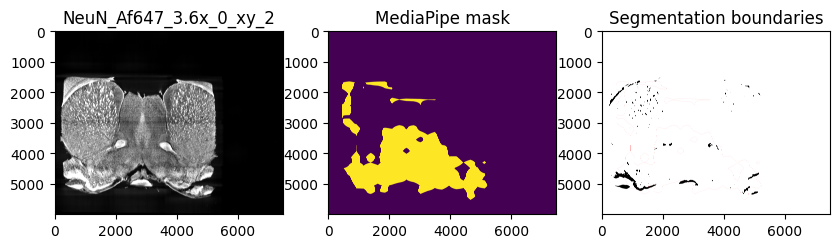

Mask 1 finished at: 02:41:49
Total Mask time: 0:00:17.088287


Mask 2 started at: 02:41:49
Shape of the Image NeuN_Af647_3.6x_1_xy_2.tiff: (5997, 7478)
Saved: NeuN_Af647_3.6x_1_xy_2_mediapipe_mask.npy — 0 pixels detected


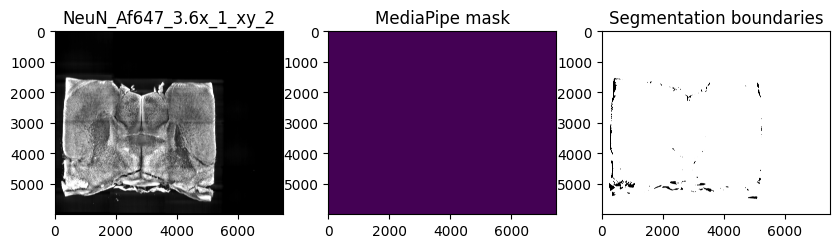

Mask 2 finished at: 02:42:03
Total Mask time: 0:00:14.140194


Mask 3 started at: 02:42:03
Shape of the Image NeuN_Af647_3.6x_2_xy_2.tiff: (5997, 7478)
Saved: NeuN_Af647_3.6x_2_xy_2_mediapipe_mask.npy — 0 pixels detected


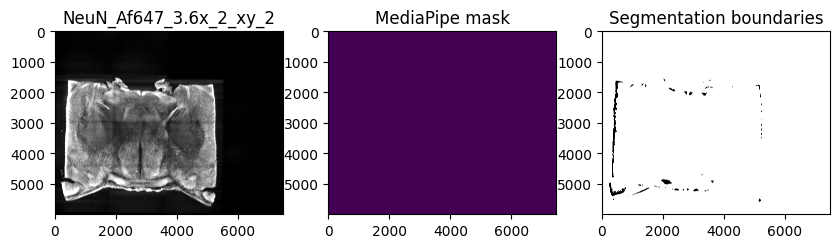

Mask 3 finished at: 02:42:15
Total Mask time: 0:00:12.218031


Mask 4 started at: 02:42:15
Shape of the Image NeuN_Af647_3.6x_3_xy_2.tiff: (5997, 7478)
Saved: NeuN_Af647_3.6x_3_xy_2_mediapipe_mask.npy — 316 pixels detected


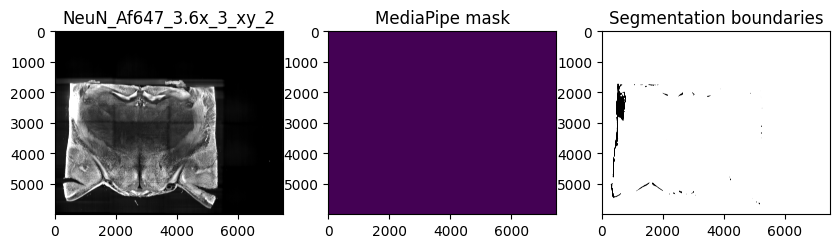

Mask 4 finished at: 02:42:29
Total Mask time: 0:00:13.539970


Mask 5 started at: 02:42:29
Shape of the Image NeuN_Af647_3.6x_4_xy_2.tiff: (5997, 7478)
Saved: NeuN_Af647_3.6x_4_xy_2_mediapipe_mask.npy — 1613276 pixels detected


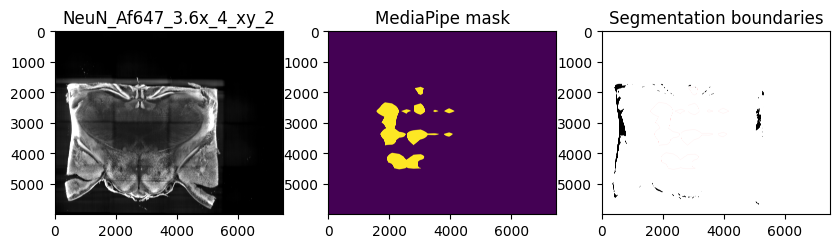

Mask 5 finished at: 02:42:44
Total Mask time: 0:00:15.542365


Mask 6 started at: 02:42:44
Shape of the Image NeuN_Af647_3.6x_5_xy_2.tiff: (5997, 7478)
Saved: NeuN_Af647_3.6x_5_xy_2_mediapipe_mask.npy — 14632790 pixels detected


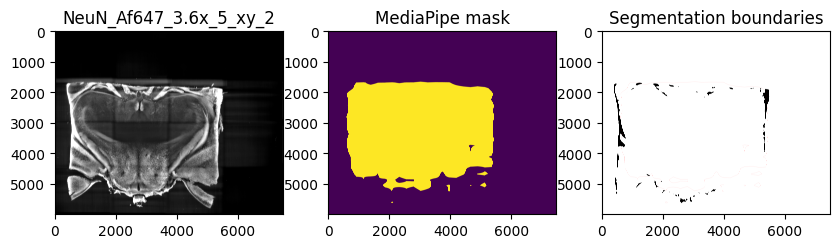

Mask 6 finished at: 02:42:57
Total Mask time: 0:00:12.358356


Mask 7 started at: 02:42:57
Shape of the Image NeuN_Af647_3.6x_6_xy_2.tiff: (5997, 7478)
Saved: NeuN_Af647_3.6x_6_xy_2_mediapipe_mask.npy — 14492848 pixels detected


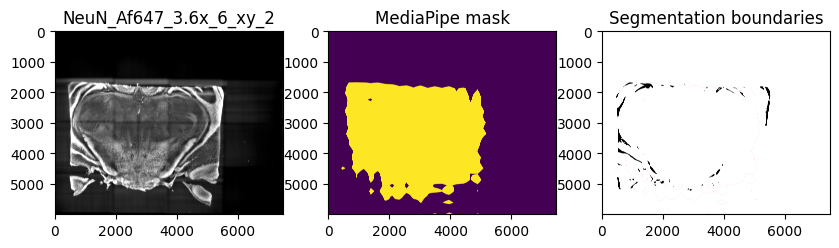

Mask 7 finished at: 02:43:11
Total Mask time: 0:00:13.909166


Mask 8 started at: 02:43:11
Shape of the Image NeuN_Af647_3.6x_7_xy_2.tiff: (5997, 7478)
Saved: NeuN_Af647_3.6x_7_xy_2_mediapipe_mask.npy — 0 pixels detected


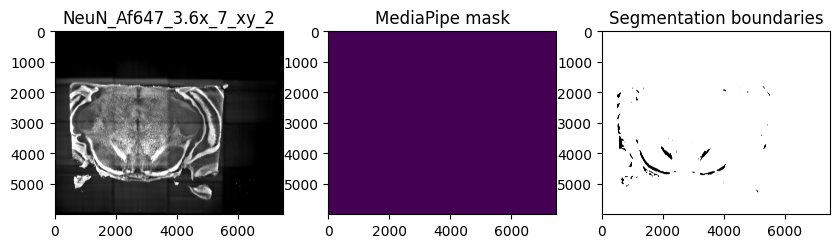

Mask 8 finished at: 02:43:25
Total Mask time: 0:00:14.655665


Mask 9 started at: 02:43:25
Shape of the Image NeuN_Af647_3.6x_8_xy_2.tiff: (5997, 7478)
Saved: NeuN_Af647_3.6x_8_xy_2_mediapipe_mask.npy — 0 pixels detected


E0000 00:00:1779093812.544162   88666 portable_clearcut_uploader.cc:90] Failed to send to clearcut: FAILED_PRECONDITION: Not valid for uploading until: 2026-05-18T02:57:32.537143-06:00
=== Source Location Trace: ===
wireless/android/play/playlog/cplusplus/portable_clearcut_uploader.cc:180


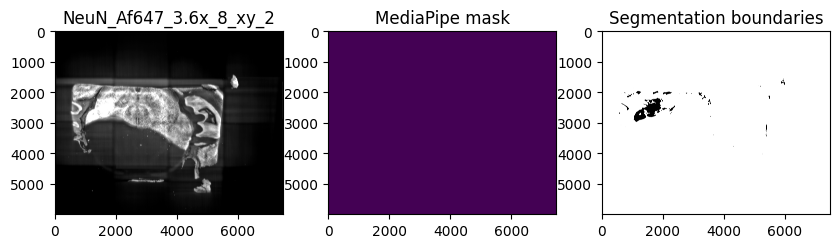

Mask 9 finished at: 02:43:38
Total Mask time: 0:00:12.861277


Mask 10 started at: 02:43:38
Shape of the Image NeuN_Af647_3.6x_9_xy_2.tiff: (5997, 7478)
Saved: NeuN_Af647_3.6x_9_xy_2_mediapipe_mask.npy — 0 pixels detected


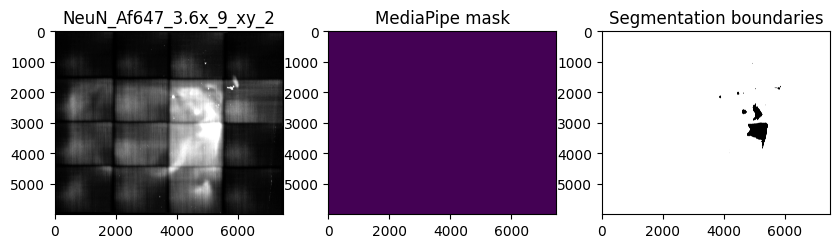

<tifffile.TiffFile 'SEG.tiff'> shaped series shape does not match page shape


Mask 10 finished at: 02:43:52
Total Mask time: 0:00:13.650921


Mask 11 started at: 02:43:52
Shape of the Image SEG.tiff: (495, 620)
Saved: SEG_mediapipe_mask.npy — 51978 pixels detected


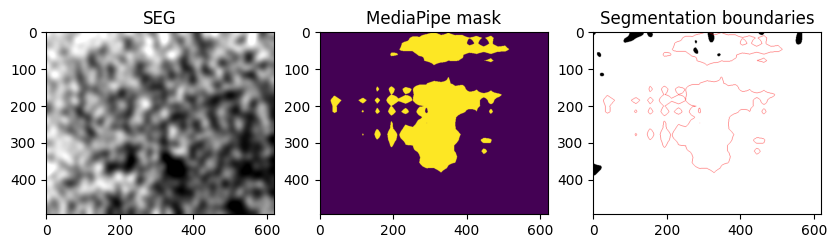

Mask 11 finished at: 02:43:52
Total Mask time: 0:00:00.273751


Finished at: 02:43:52
Total time: 0:02:20.284465


E0000 00:00:1779093832.531608   88666 portable_clearcut_uploader.cc:90] Failed to send to clearcut: FAILED_PRECONDITION: Not valid for uploading until: 2026-05-18T02:57:32.537143-06:00
=== Source Location Trace: ===
wireless/android/play/playlog/cplusplus/portable_clearcut_uploader.cc:180


In [21]:
start = datetime.now()
print(f"Started at: {start.strftime('%H:%M:%S')}\n")

base_options = python.BaseOptions(model_asset_path='deeplabv3.tflite')
options = vision.ImageSegmenterOptions(base_options=base_options,
                                       output_category_mask=True)

with vision.ImageSegmenter.create_from_options(options) as segmenter:

    tiff_paths = sorted(glob.glob("*.tiff")) # Get all images

    for i, path in enumerate(tiff_paths):
        start_t = datetime.now()
        print(f"\nMask {(i+1)} started at: {start_t.strftime('%H:%M:%S')}")
        
        img = tifffile.imread(path)  # Read images (H, W)
        
        print(f"Shape of the Image {path}: {img.shape}")
        
        img = preprocess_dots(img)
        img = gaussian_filter(img,10)
        
        low  = np.percentile(img, 1)
        high = np.percentile(img, 99)
        img = np.clip((img - low) / (high - low) * 255, 0, 255).astype(np.uint8)
        
        img_rgb = np.stack([img, img, img], axis=-1)

        image = mp.Image(image_format=mp.ImageFormat.SRGB, data=img_rgb)
        
        segmentation_result = segmenter.segment(image)
        category_mask = segmentation_result.category_mask
        seg = np.int16(category_mask.numpy_view().squeeze(-1) > 0)
        
        
        # Save the mask
        base, ext = os.path.splitext(path)
        mask_path = f"{base}_mediapipe_mask.npy"
        np.save(mask_path, seg.astype(np.uint16))
        print(f"Saved: {mask_path} — {seg.sum()} pixels detected")
        
        low  = img.max()
        high = img.min()
        img_norm = np.clip((img - low) / (high - low), 0, 1)
        boundaries = find_boundaries(seg, mode='outer')
        rgb = np.stack([img_norm, img_norm, img_norm], axis=-1)  # grayscale as RGB
        rgb[boundaries] = [1, 0, 0]  # paint outlines red
        
        #Print Images and their masks
        fig, ax = plt.subplots(1, 3, figsize=(10, 6))
        ax[0].imshow(img, cmap='gray')
        ax[0].set_title(f'{base}')
        ax[1].imshow(seg)  # tab20 gives each cell a different color
        ax[1].set_title(f'MediaPipe mask')
        ax[2].imshow(rgb)
        ax[2].set_title(f'Segmentation boundaries')
        plt.show()
        
        end_t = datetime.now()
        print(f"Mask {(i+1)} finished at: {end_t.strftime('%H:%M:%S')}")
        print(f"Total Mask time: {end_t - start_t}\n")
        
    end = datetime.now()
    print(f"\nFinished at: {end.strftime('%H:%M:%S')}")
    print(f"Total time: {end - start}")

### Segmentate Anything Model

#### Original Segmentation

Started at: 02:29:53


Mask 1 started at: 02:29:59
Shape of the Image NeuN_Af647_3.6x_0_xy_4.tiff: (749, 934)
SAM2 found 17 regions
Mask 1 finished at: 02:30:25
Total Mask time: 0:00:25.759688


Mask 2 started at: 02:30:25
Shape of the Image NeuN_Af647_3.6x_0_xz_4.tiff: (559, 934)
SAM2 found 7 regions
Mask 2 finished at: 02:30:43
Total Mask time: 0:00:18.563582


Mask 3 started at: 02:30:43
Shape of the Image NeuN_Af647_3.6x_0_yz_4.tiff: (559, 749)
SAM2 found 4 regions
Mask 3 finished at: 02:31:01
Total Mask time: 0:00:17.907412


Mask 4 started at: 02:31:01
Shape of the Image NeuN_Af647_3.6x_1_xy_4.tiff: (749, 934)
SAM2 found 17 regions
Mask 4 finished at: 02:31:22
Total Mask time: 0:00:21.027964


Mask 5 started at: 02:31:22
Shape of the Image NeuN_Af647_3.6x_1_xz_4.tiff: (559, 934)
SAM2 found 5 regions
Mask 5 finished at: 02:31:44
Total Mask time: 0:00:21.626059


Mask 6 started at: 02:31:44
Shape of the Image NeuN_Af647_3.6x_1_yz_4.tiff: (559, 749)
SAM2 found 5 regions
Mask 6 finis

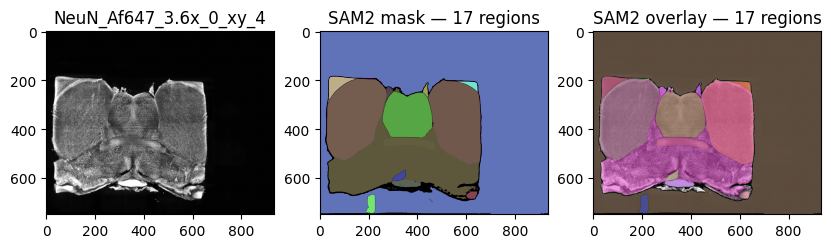

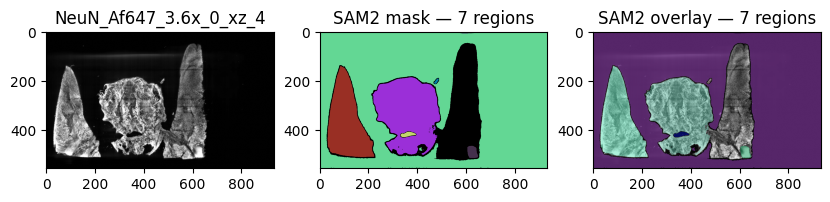

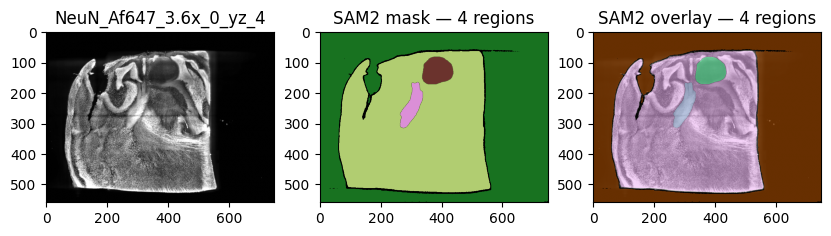

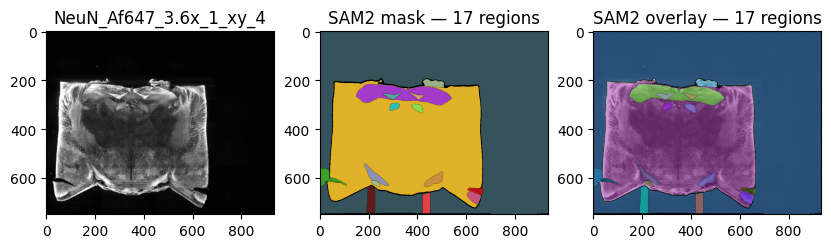

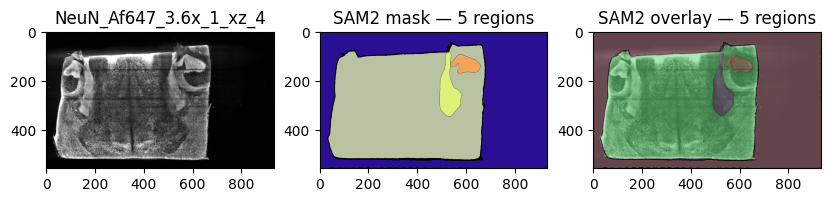

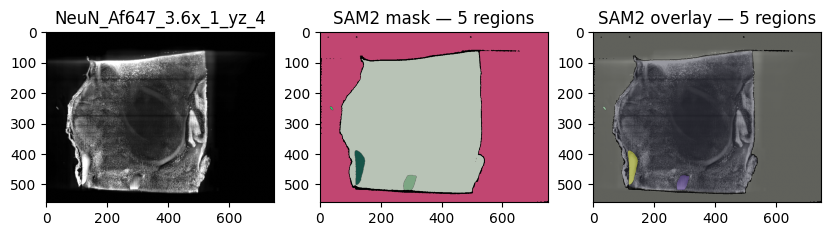

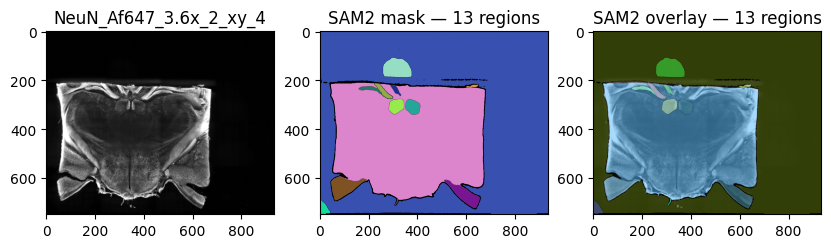

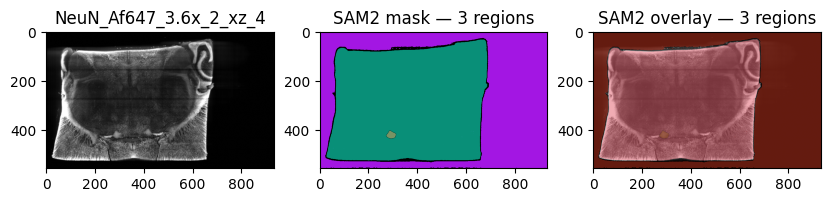

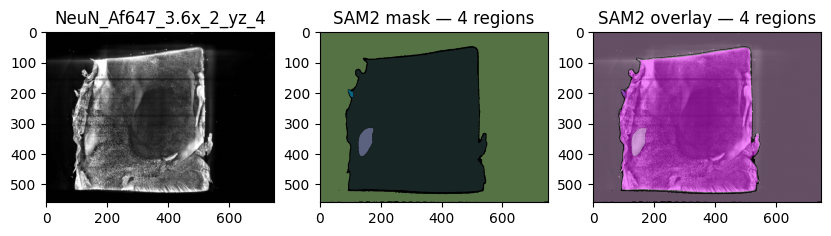

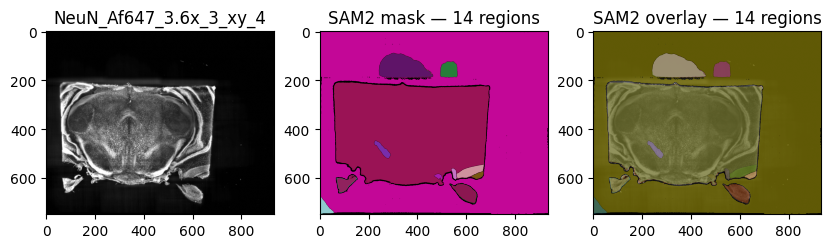

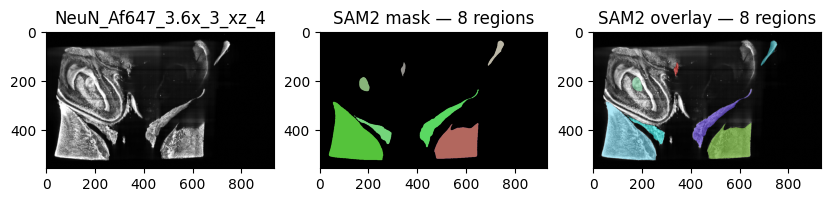

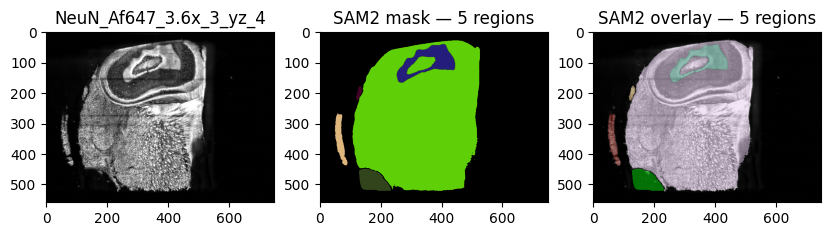

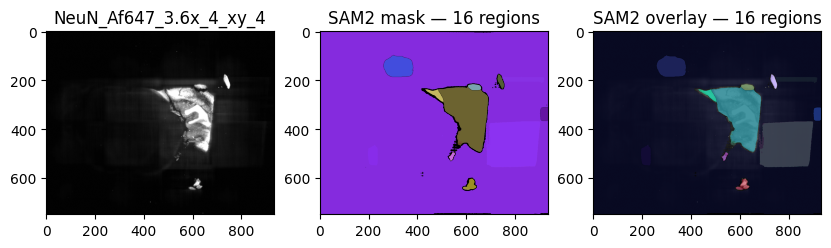

In [7]:
start = datetime.now()
print(f"Started at: {start.strftime('%H:%M:%S')}\n")

# Load SAM2 model
sam2_model = build_sam2(
    config_file="sam2_hiera_l.yaml",
    ckpt_path="sam2_hiera_large.pt",
    device="mps"   # use "cpu" if no GPU
)

mask_generator = SAM2AutomaticMaskGenerator(
    model=sam2_model,
    points_per_side=32,
    pred_iou_thresh=0.8,
    stability_score_thresh=0.9,
    min_mask_region_area=50
)


tiff_paths = sorted(glob.glob("*.tiff")) # Get all images

for i, path in enumerate(tiff_paths):
    start_t = datetime.now()
    print(f"\nMask {(i+1)} started at: {start_t.strftime('%H:%M:%S')}")
    
    img = tifffile.imread(path)  # Read images (H, W)
    
    print(f"Shape of the Image {path}: {img.shape}")
    
    img = preprocess_dots(img)

    img_rgb = np.stack([img, img, img], axis=-1)

    # Generate masks automatically
    masks = mask_generator.generate(img_rgb)
    print(f"SAM2 found {len(masks)} regions")
    
    #Print Images and their masks
    base, ext = os.path.splitext(path)
    fig, ax = plt.subplots(1, 3, figsize=(10, 6))
    ax[0].imshow(img, cmap='gray')
    ax[0].set_title(f'{base}')
   
    ax[1].imshow(np.zeros((*img.shape, 3)))
    for mask_dict in masks:
        mask = mask_dict['segmentation']
        color = np.random.random(3)
        overlay = np.zeros((*mask.shape, 4))
        overlay[mask] = [*color, 0.9]          # more opaque on black
        ax[1].imshow(overlay)
    ax[1].set_title(f'SAM2 mask — {len(masks)} regions')

    # Panel 3 — overlay on original image
    ax[2].imshow(img, cmap='gray')
    for mask_dict in masks:
        mask = mask_dict['segmentation']
        color = np.random.random(3)
        overlay = np.zeros((*mask.shape, 4))
        overlay[mask] = [*color, 0.5]          # semi-transparent on image
        ax[2].imshow(overlay)
    ax[2].set_title(f'SAM2 overlay — {len(masks)} regions')
    
    end_t = datetime.now()
    print(f"Mask {(i+1)} finished at: {end_t.strftime('%H:%M:%S')}")
    print(f"Total Mask time: {end_t - start_t}\n")
    
end = datetime.now()
print(f"\nFinished at: {end.strftime('%H:%M:%S')}")
print(f"Total time: {end - start}")

#### Comparasion

Started at: 02:48:25


Mask 1 started at: 02:48:34
Shape of the Image NeuN_Af647_3.6x_0_xy_4.tiff: (495, 632)
SAM2 found 11 regions
Mask 1 finished at: 02:50:12
Total Mask time: 0:01:38.068384


Mask 2 started at: 02:50:12
Shape of the Image NeuN_Af647_3.6x_0_xz_4.tiff: (430, 625)
SAM2 found 10 regions
Mask 2 finished at: 02:51:37
Total Mask time: 0:01:24.536970


Mask 3 started at: 02:51:37
Shape of the Image NeuN_Af647_3.6x_0_yz_4.tiff: (464, 497)
SAM2 found 7 regions
Mask 3 finished at: 02:52:32
Total Mask time: 0:00:55.423566


Mask 4 started at: 02:52:32
Shape of the Image NeuN_Af647_3.6x_1_xy_4.tiff: (495, 634)
SAM2 found 9 regions
Mask 4 finished at: 02:53:23
Total Mask time: 0:00:50.859157


Mask 5 started at: 02:53:23
Shape of the Image NeuN_Af647_3.6x_1_xz_4.tiff: (466, 642)
SAM2 found 7 regions
Mask 5 finished at: 02:54:27
Total Mask time: 0:01:04.273230


Mask 6 started at: 02:54:27
Shape of the Image NeuN_Af647_3.6x_1_yz_4.tiff: (462, 476)
SAM2 found 4 regions
Mask 6 finis

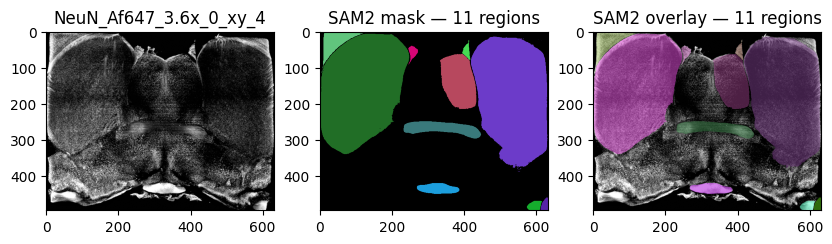

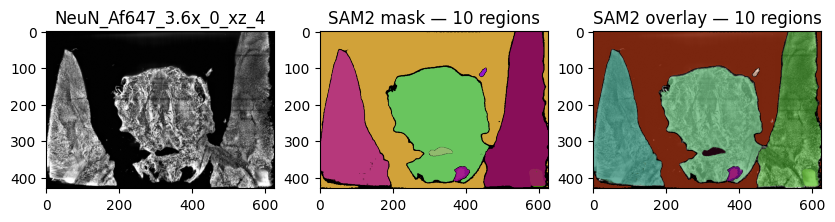

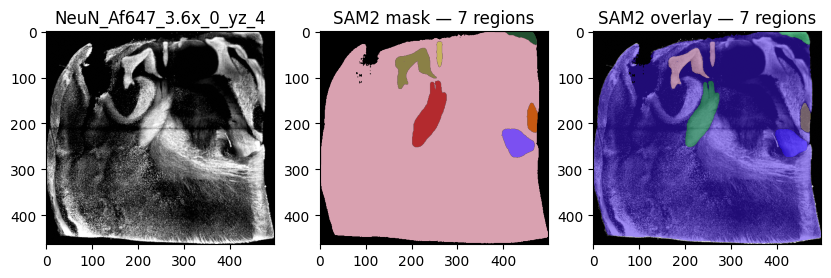

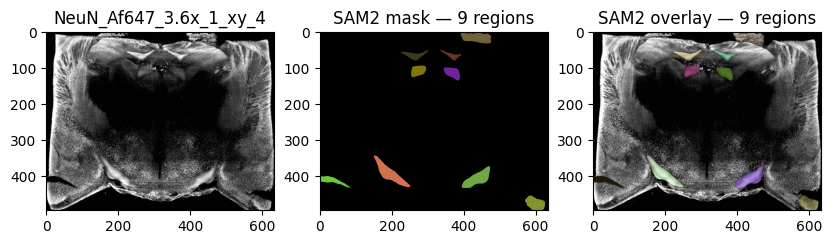

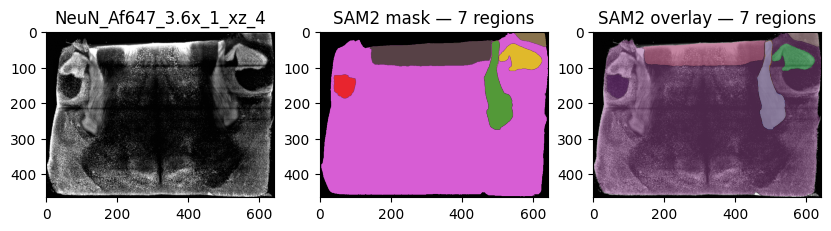

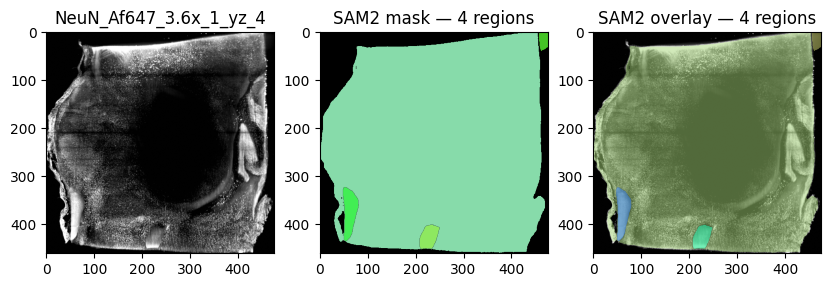

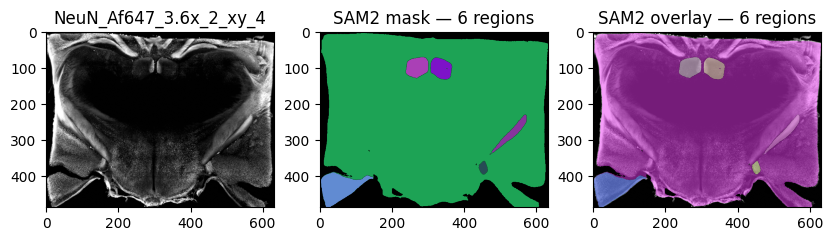

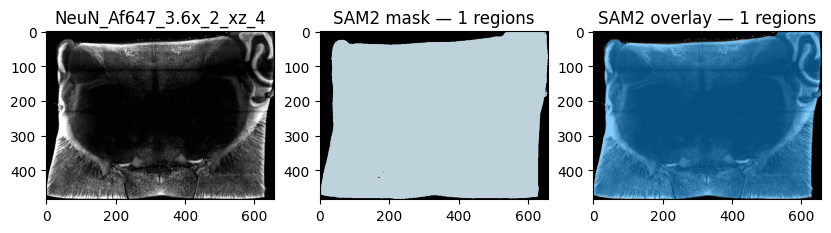

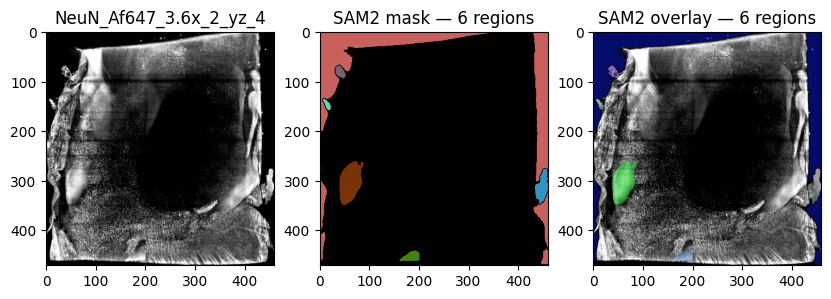

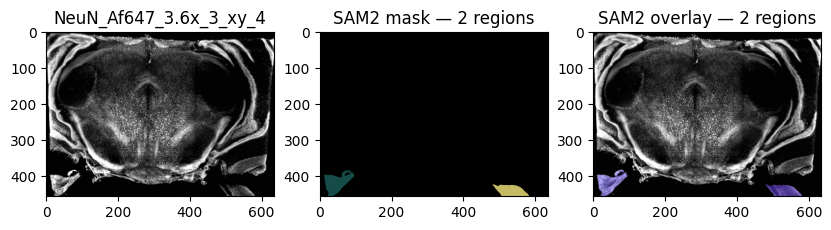

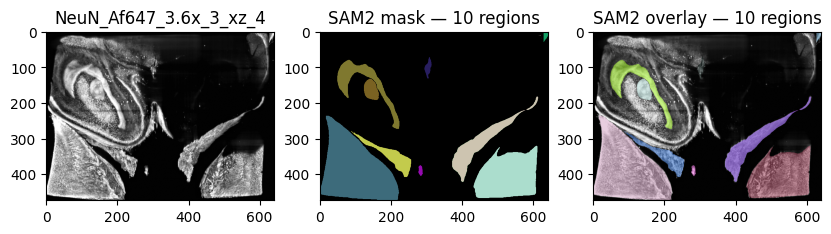

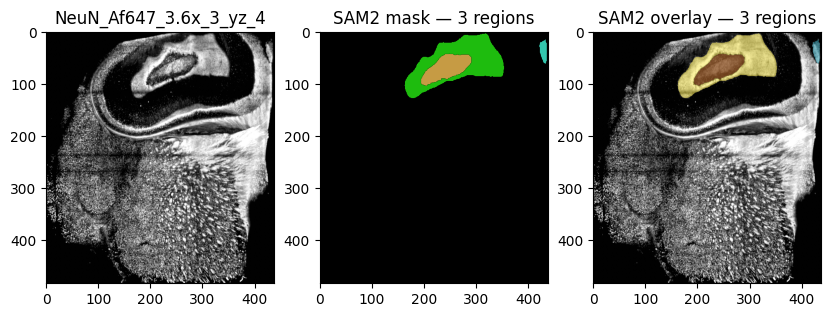

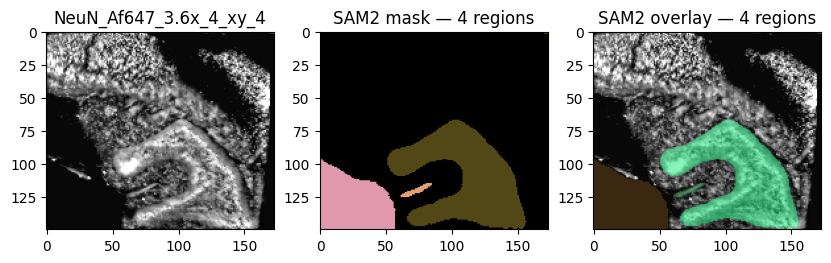

In [9]:
start = datetime.now()
print(f"Started at: {start.strftime('%H:%M:%S')}\n")

# Load SAM2 model
sam2_model = build_sam2(
    config_file="sam2_hiera_l.yaml",
    ckpt_path="sam2_hiera_large.pt",
    device="mps"   # use "cpu" if no GPU
)

mask_generator = SAM2AutomaticMaskGenerator(
    model=sam2_model,
    points_per_side=32,
    pred_iou_thresh=0.8,
    stability_score_thresh=0.9,
    min_mask_region_area=50
)


tiff_paths = sorted(glob.glob("*.tiff")) # Get all images

for i, path in enumerate(tiff_paths):
    start_t = datetime.now()
    print(f"\nMask {(i+1)} started at: {start_t.strftime('%H:%M:%S')}")
    
    img = tifffile.imread(path)  # Read images (H, W)
    
    print(f"Shape of the Image {path}: {img.shape}")
    
    img = preprocess_dots(img)

    img_rgb = np.stack([img, img, img], axis=-1)

    # Generate masks automatically
    masks = mask_generator.generate(img_rgb)
    print(f"SAM2 found {len(masks)} regions")
    
    #Print Images and their masks
    base, ext = os.path.splitext(path)
    fig, ax = plt.subplots(1, 3, figsize=(10, 6))
    ax[0].imshow(img, cmap='gray')
    ax[0].set_title(f'{base}')
   
    ax[1].imshow(np.zeros((*img.shape, 3)))
    for mask_dict in masks:
        mask = mask_dict['segmentation']
        color = np.random.random(3)
        overlay = np.zeros((*mask.shape, 4))
        overlay[mask] = [*color, 0.9]          # more opaque on black
        ax[1].imshow(overlay)
    ax[1].set_title(f'SAM2 mask — {len(masks)} regions')

    # Panel 3 — overlay on original image
    ax[2].imshow(img, cmap='gray')
    for mask_dict in masks:
        mask = mask_dict['segmentation']
        color = np.random.random(3)
        overlay = np.zeros((*mask.shape, 4))
        overlay[mask] = [*color, 0.5]          # semi-transparent on image
        ax[2].imshow(overlay)
    ax[2].set_title(f'SAM2 overlay — {len(masks)} regions')
    
    end_t = datetime.now()
    print(f"Mask {(i+1)} finished at: {end_t.strftime('%H:%M:%S')}")
    print(f"Total Mask time: {end_t - start_t}\n")
    
end = datetime.now()
print(f"\nFinished at: {end.strftime('%H:%M:%S')}")
print(f"Total time: {end - start}")

Started at: 08:14:45


Mask 1 started at: 08:14:47
Shape of the Image NeuN_Af647_3.6x_10_xy_0.tiff: (1600, 2000)


/Users/ivan/Pictures/Mis Cosas/Cosas del Trabajo/UTEP/SNL/Repositories/imaris-cross-section/venv/lib/python3.14/site-packages/sam2/sam2_image_predictor.py:431: UserWarning: cannot import name '_C' from 'sam2' (/Users/ivan/Pictures/Mis Cosas/Cosas del Trabajo/UTEP/SNL/Repositories/imaris-cross-section/venv/lib/python3.14/site-packages/sam2/__init__.py)

Skipping the post-processing step due to the error above. You can still use SAM 2 and it's OK to ignore the error above, although some post-processing functionality may be limited (which doesn't affect the results in most cases; see https://github.com/facebookresearch/sam2/blob/main/INSTALL.md).
  masks = self._transforms.postprocess_masks(


SAM2 found 18 regions
Mask 1 finished at: 08:15:11
Total Mask time: 0:00:24.085855


Mask 2 started at: 08:15:11
Shape of the Image NeuN_Af647_3.6x_11_xy_0.tiff: (1600, 2000)
SAM2 found 34 regions
Mask 2 finished at: 08:17:44
Total Mask time: 0:02:33.159927


Mask 3 started at: 08:17:45
Shape of the Image NeuN_Af647_3.6x_12_xy_0.tiff: (1600, 2000)


KeyboardInterrupt: 

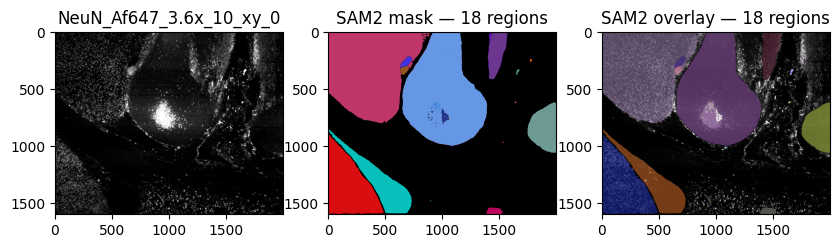

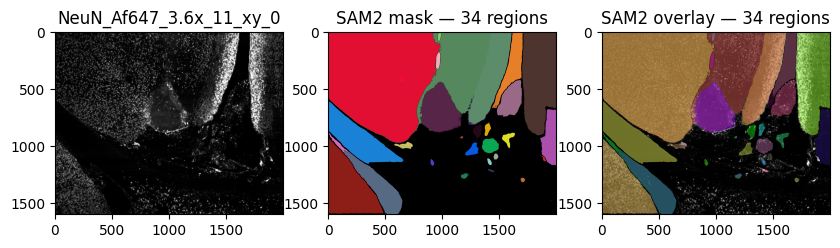

In [5]:
start = datetime.now()
print(f"Started at: {start.strftime('%H:%M:%S')}\n")

# Load SAM2 model
sam2_model = build_sam2(
    config_file="sam2_hiera_l.yaml",
    ckpt_path="sam2_hiera_large.pt",
    device="mps"   # use "cpu" if no GPU
)

mask_generator = SAM2AutomaticMaskGenerator(
    model=sam2_model,
    points_per_side=32,
    pred_iou_thresh=0.8,
    stability_score_thresh=0.9,
    min_mask_region_area=50
)


tiff_paths = sorted(glob.glob("*.tiff")) # Get all images

for i, path in enumerate(tiff_paths):
    start_t = datetime.now()
    print(f"\nMask {(i+1)} started at: {start_t.strftime('%H:%M:%S')}")
    
    img = tifffile.imread(path)  # Read images (H, W)
    
    print(f"Shape of the Image {path}: {img.shape}")
    
    img = preprocess_dots(img)

    img_rgb = np.stack([img, img, img], axis=-1)

    # Generate masks automatically
    masks = mask_generator.generate(img_rgb)
    print(f"SAM2 found {len(masks)} regions")
    
    #Print Images and their masks
    base, ext = os.path.splitext(path)
    fig, ax = plt.subplots(1, 3, figsize=(10, 6))
    ax[0].imshow(img, cmap='gray')
    ax[0].set_title(f'{base}')
   
    ax[1].imshow(np.zeros((*img.shape, 3)))
    for mask_dict in masks:
        mask = mask_dict['segmentation']
        color = np.random.random(3)
        overlay = np.zeros((*mask.shape, 4))
        overlay[mask] = [*color, 0.9]          # more opaque on black
        ax[1].imshow(overlay)
    ax[1].set_title(f'SAM2 mask — {len(masks)} regions')

    # Panel 3 — overlay on original image
    ax[2].imshow(img, cmap='gray')
    for mask_dict in masks:
        mask = mask_dict['segmentation']
        color = np.random.random(3)
        overlay = np.zeros((*mask.shape, 4))
        overlay[mask] = [*color, 0.5]          # semi-transparent on image
        ax[2].imshow(overlay)
    ax[2].set_title(f'SAM2 overlay — {len(masks)} regions')
    
    end_t = datetime.now()
    print(f"Mask {(i+1)} finished at: {end_t.strftime('%H:%M:%S')}")
    print(f"Total Mask time: {end_t - start_t}\n")
    
end = datetime.now()
print(f"\nFinished at: {end.strftime('%H:%M:%S')}")
print(f"Total time: {end - start}")

### Cellpose

Started at: 11:23:42


Mask 1 started at: 11:23:44
Shape of the Image NeuN_Af647_3.6x_0_xy_2.tiff: (5997, 7478)


/Users/ivan/Pictures/Mis Cosas/Cosas del Trabajo/UTEP/SNL/Repositories/imaris-cross-section/venv/lib/python3.14/site-packages/cellpose/dynamics.py:524: UserWarning: Sparse invariant checks are implicitly disabled. Memory errors (e.g. SEGFAULT) will occur when operating on a sparse tensor which violates the invariants, but checks incur performance overhead. To silence this warning, explicitly opt in or out. See `torch.sparse.check_sparse_tensor_invariants.__doc__` for guidance.  (Triggered internally at /Users/runner/work/pytorch/pytorch/aten/src/ATen/Context.cpp:767.)
  coo = torch.sparse_coo_tensor(pt, torch.ones(pt.shape[1], device=pt.device, dtype=torch.int),
more than 65535 masks in image, masks returned as np.uint32


Saved: NeuN_Af647_3.6x_0_xy_2_cellpose_mask.npy — 101007 cells detected


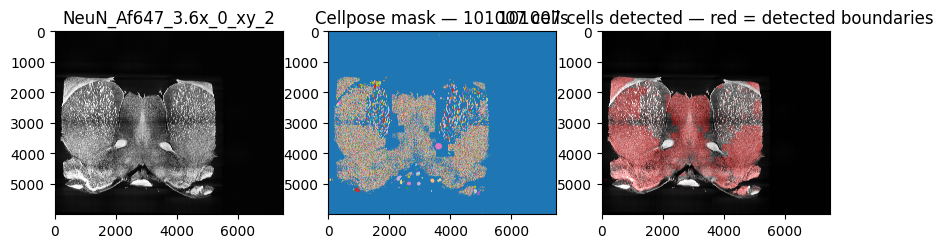

Mask 1 finished at: 11:40:03
Total Mask time: 0:16:18.779798


Mask 2 started at: 11:40:03
Shape of the Image NeuN_Af647_3.6x_1_xy_2.tiff: (5997, 7478)


more than 65535 masks in image, masks returned as np.uint32


Saved: NeuN_Af647_3.6x_1_xy_2_cellpose_mask.npy — 156694 cells detected


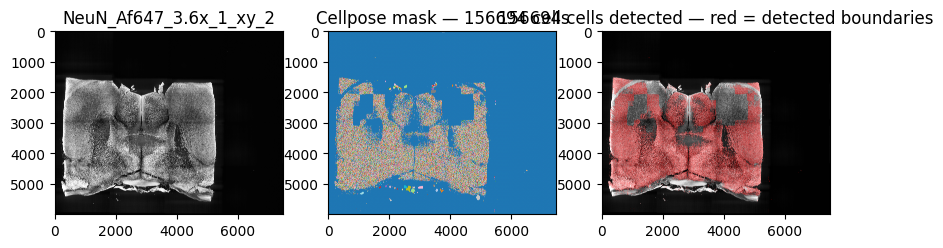

Mask 2 finished at: 11:56:11
Total Mask time: 0:16:08.263273


Mask 3 started at: 11:56:11
Shape of the Image NeuN_Af647_3.6x_2_xy_2.tiff: (5997, 7478)


more than 65535 masks in image, masks returned as np.uint32


Saved: NeuN_Af647_3.6x_2_xy_2_cellpose_mask.npy — 110659 cells detected


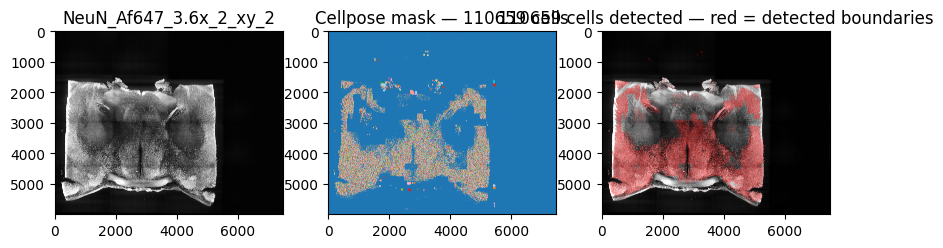

Mask 3 finished at: 12:12:18
Total Mask time: 0:16:07.046918


Mask 4 started at: 12:12:18
Shape of the Image NeuN_Af647_3.6x_3_xy_2.tiff: (5997, 7478)


more than 65535 masks in image, masks returned as np.uint32


Saved: NeuN_Af647_3.6x_3_xy_2_cellpose_mask.npy — 76799 cells detected


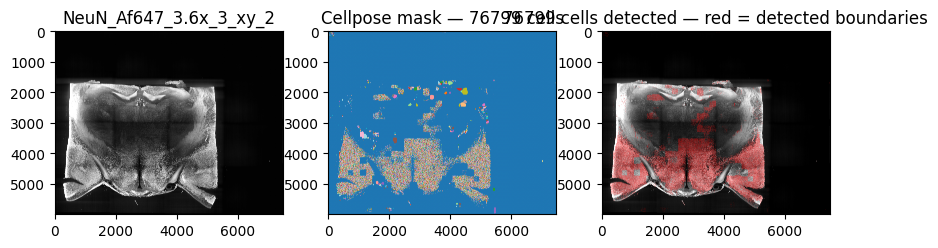

Mask 4 finished at: 12:28:24
Total Mask time: 0:16:05.475394


Mask 5 started at: 12:28:24
Shape of the Image NeuN_Af647_3.6x_4_xy_2.tiff: (5997, 7478)
Saved: NeuN_Af647_3.6x_4_xy_2_cellpose_mask.npy — 59422 cells detected


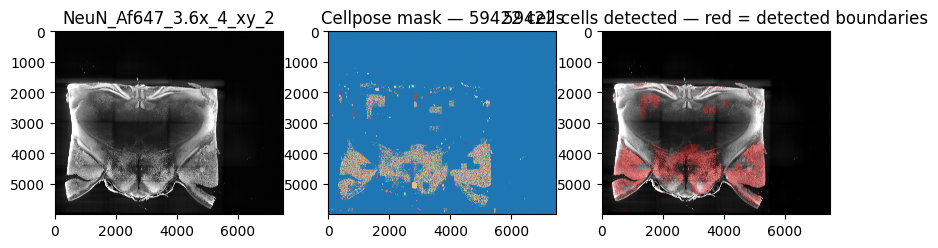

Mask 5 finished at: 12:44:06
Total Mask time: 0:15:42.081383


Mask 6 started at: 12:44:06
Shape of the Image NeuN_Af647_3.6x_5_xy_2.tiff: (5997, 7478)
Saved: NeuN_Af647_3.6x_5_xy_2_cellpose_mask.npy — 31356 cells detected


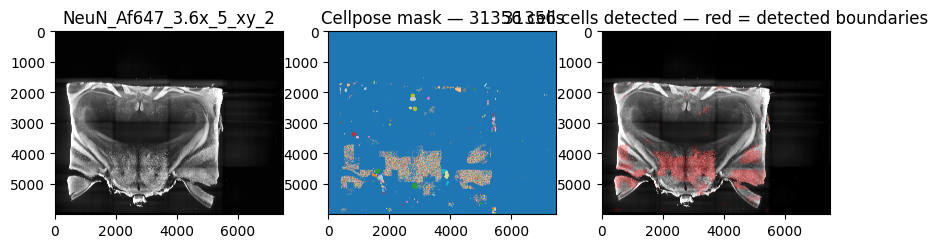

Mask 6 finished at: 12:59:40
Total Mask time: 0:15:33.785199


Mask 7 started at: 12:59:40
Shape of the Image NeuN_Af647_3.6x_6_xy_2.tiff: (5997, 7478)
Saved: NeuN_Af647_3.6x_6_xy_2_cellpose_mask.npy — 22494 cells detected


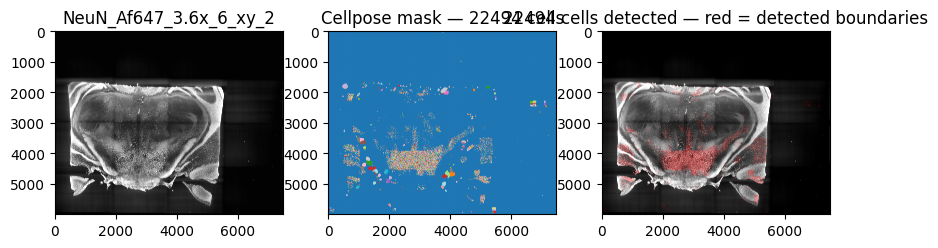

Mask 7 finished at: 13:15:14
Total Mask time: 0:15:34.116126


Mask 8 started at: 13:15:14
Shape of the Image NeuN_Af647_3.6x_7_xy_2.tiff: (5997, 7478)
Saved: NeuN_Af647_3.6x_7_xy_2_cellpose_mask.npy — 23075 cells detected


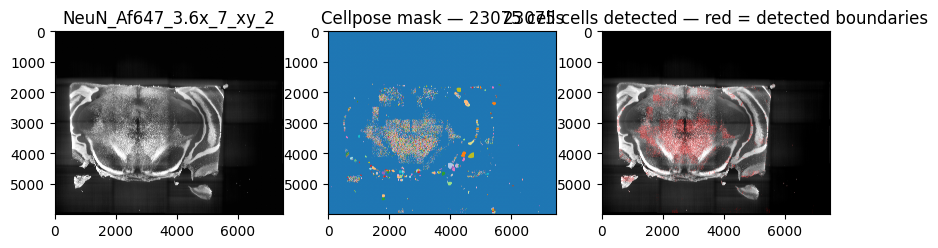

Mask 8 finished at: 13:30:43
Total Mask time: 0:15:29.461788


Mask 9 started at: 13:30:43
Shape of the Image NeuN_Af647_3.6x_8_xy_2.tiff: (5997, 7478)
Saved: NeuN_Af647_3.6x_8_xy_2_cellpose_mask.npy — 5571 cells detected


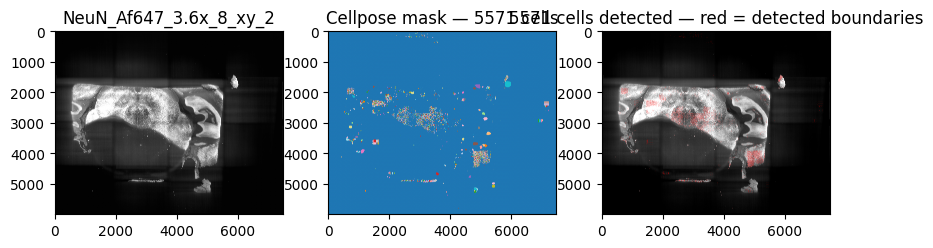

Mask 9 finished at: 13:46:02
Total Mask time: 0:15:18.426161


Mask 10 started at: 13:46:02
Shape of the Image NeuN_Af647_3.6x_9_xy_2.tiff: (5997, 7478)
Saved: NeuN_Af647_3.6x_9_xy_2_cellpose_mask.npy — 444 cells detected


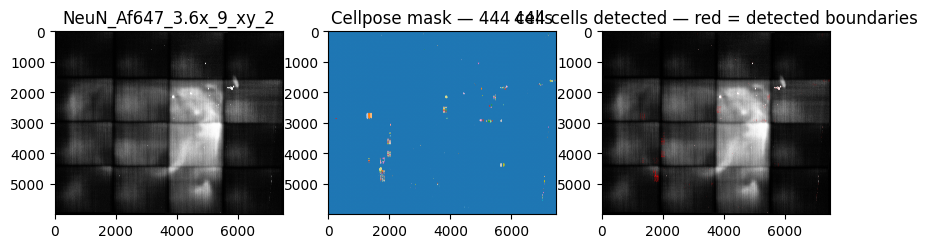

<tifffile.TiffFile 'SEG.tiff'> shaped series shape does not match page shape


Mask 10 finished at: 14:01:04
Total Mask time: 0:15:01.722031


Mask 11 started at: 14:01:04
Shape of the Image SEG.tiff: (495, 620)
Saved: SEG_cellpose_mask.npy — 1643 cells detected


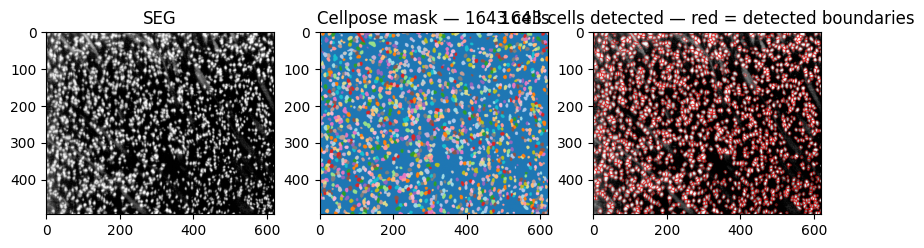

Mask 11 finished at: 14:01:15
Total Mask time: 0:00:11.469643


Finished at: 14:01:15
Total time: 2:37:32.733792


In [13]:
start = datetime.now()
print(f"Started at: {start.strftime('%H:%M:%S')}\n")

tiff_paths = sorted(glob.glob("*.tiff")) # Get all images

model = models.CellposeModel(gpu=True) # Define CellPose model

for i, path in enumerate(tiff_paths):
    start_t = datetime.now()
    print(f"\nMask {(i+1)} started at: {start_t.strftime('%H:%M:%S')}")
    
    img = tifffile.imread(path)  # Read images (H, W)
    
    print(f"Shape of the Image {path}: {img.shape}")
    
    img = preprocess_dots(img)

    masks, flows, styles = model.eval(
        img,
        diameter=30,
        flow_threshold=0.9,
        cellprob_threshold=-2,
        normalize={"lowhigh": (0, 300)},
        resample=True
    )
    
    # Save the mask
    base, ext = os.path.splitext(path)
    mask_path = f"{base}_cellpose_mask.npy"
    tifffile.imwrite(mask_path, masks.astype(np.uint16))
    print(f"Saved: {mask_path} — {masks.max()} cells detected")
    
    low  = np.percentile(img, 1)
    high = np.percentile(img, 99)
    img_norm = np.clip((img - low) / (high - low), 0, 1)
    boundaries = find_boundaries(masks, mode='outer')
    rgb = np.stack([img_norm, img_norm, img_norm], axis=-1)  # grayscale as RGB
    rgb[boundaries] = [1, 0, 0]  # paint outlines red
    
    #Print Images and their masks
    fig, ax = plt.subplots(1, 3, figsize=(10, 6))
    ax[0].imshow(img, cmap='gray')
    ax[0].set_title(f'{base}')
    ax[1].imshow(masks % 20, cmap='tab20')  # tab20 gives each cell a different color
    ax[1].set_title(f'Cellpose mask — {masks.max()} cells')
    ax[2].imshow(rgb)
    ax[2].set_title(f'{masks.max()} cells detected — red = detected boundaries')
    plt.show()
    
    end_t = datetime.now()
    print(f"Mask {(i+1)} finished at: {end_t.strftime('%H:%M:%S')}")
    print(f"Total Mask time: {end_t - start_t}\n")
    
end = datetime.now()
print(f"\nFinished at: {end.strftime('%H:%M:%S')}")
print(f"Total time: {end - start}")

In [ ]:
start = datetime.now()
print(f"Started at: {start.strftime('%H:%M:%S')}\n")

tiff_paths = sorted(glob.glob("./Seg-Results/*.tiff")) # Get all images

model = models.CellposeModel(gpu=True) # Define CellPose model

for i, path in enumerate(tiff_paths):

    img = tifffile.imread(path)
    base, ext = os.path.splitext(path)
    
    mask_path = f"{base}_cellpose_mask.npy"  # adjust naming convention as needed

    mask = np.load(mask_path)
    
    low  = np.percentile(img, 1)
    high = np.percentile(img, 99)
    img_norm = np.clip((img - low) / (high - low), 0, 1)
    boundaries = find_boundaries(masks, mode='outer')
    rgb = np.stack([img_norm, img_norm, img_norm], axis=-1)  # grayscale as RGB
    rgb[boundaries] = [1, 0, 0]  # paint outlines red
    
    fig, ax = plt.subplots(1, 3, figsize=(20, 12))
    ax[0].imshow(img, cmap='gray')
    ax[0].set_title(f'{base}')
    ax[1].imshow(masks % 20, cmap='tab20')  # tab20 gives each cell a different color
    ax[1].set_title(f'Cellpose mask — {masks.max()} cells')
    ax[2].imshow(rgb)
    ax[2].set_title(f'{masks.max()} cells detected — red = detected boundaries')
    plt.show()